# PRML Lab 4 — Bayes Classification
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold

# numpy 2 on macOS Accelerate emits spurious matmul RuntimeWarnings inside sklearn; results are unaffected
warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
SEED = 56
sns.set_theme(style='whitegrid')
results = {}

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

# Question 1 — Naive Bayes on Titanic

### 1. Pre-processing, visualisation, column selection and split

In [2]:
titanic = pd.read_csv('data/titanic.csv')
print(titanic.shape)
print(titanic.isna().sum()[titanic.isna().sum() > 0])
titanic.head()

(891, 10)
Age         177
Cabin       687
Embarked      2
dtype: int64


,PassengerId,Name,Pclass,Sex,Age,Ticket,Fare,Cabin,Embarked,Survived
0,1,"Braund, Mr. Owen Harris",3,male,22.0,A/5 21171,7.2500,NaN,S,0
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,female,38.0,PC 17599,71.2833,C85,C,1
2,3,"Heikkinen, Miss. Laina",3,female,26.0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,female,35.0,113803,53.1000,C123,S,1
4,5,"Allen, Mr. William Henry",3,male,35.0,373450,8.0500,NaN,S,0


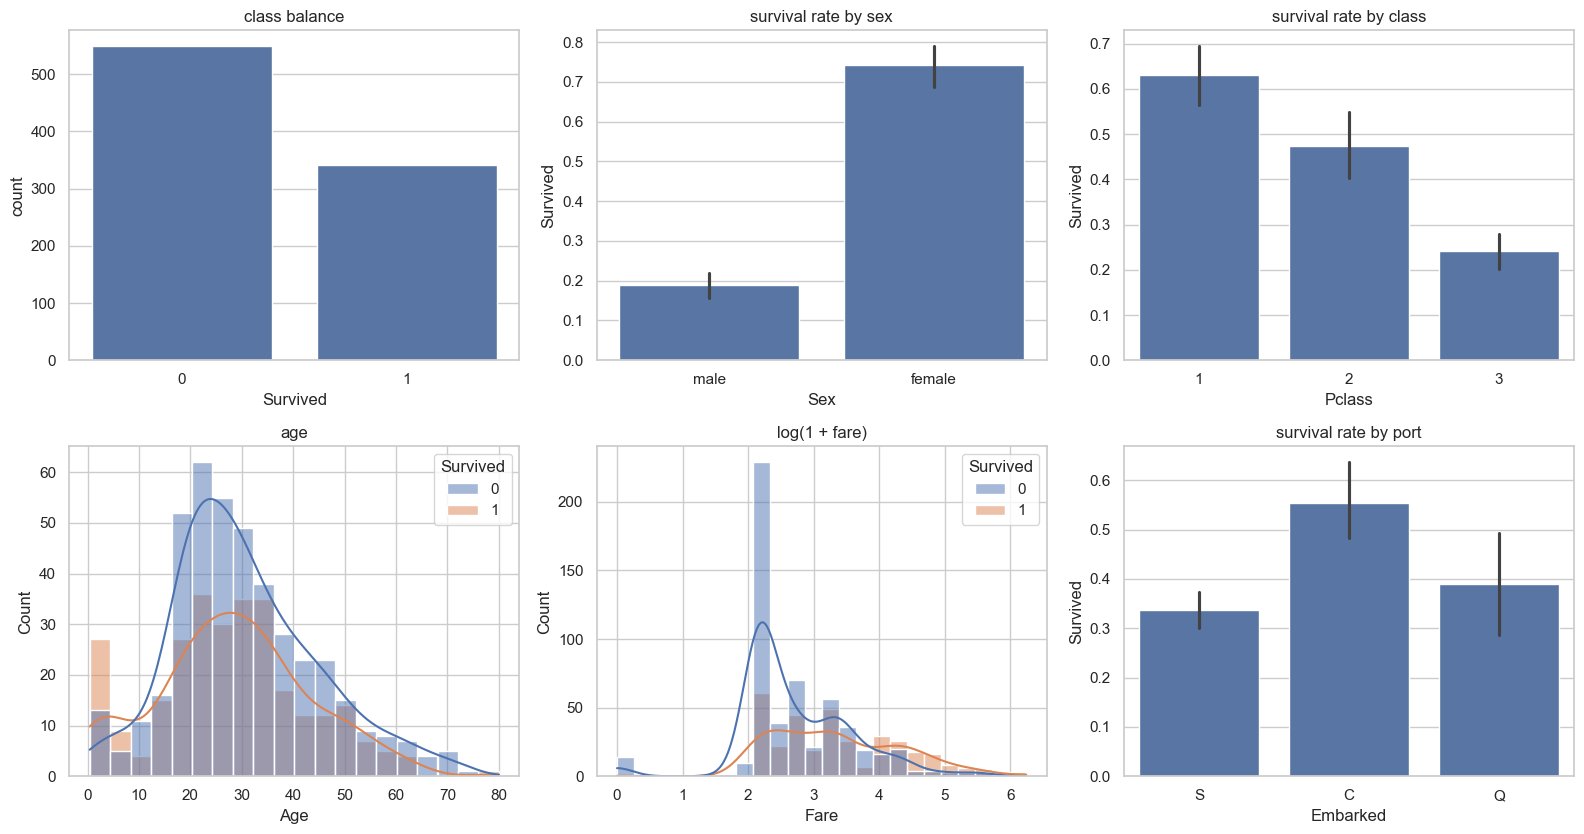

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
sns.countplot(data=titanic, x='Survived', ax=ax[0, 0]); ax[0, 0].set_title('class balance')
sns.barplot(data=titanic, x='Sex', y='Survived', ax=ax[0, 1]); ax[0, 1].set_title('survival rate by sex')
sns.barplot(data=titanic, x='Pclass', y='Survived', ax=ax[0, 2]); ax[0, 2].set_title('survival rate by class')
sns.histplot(data=titanic, x='Age', hue='Survived', kde=True, ax=ax[1, 0]); ax[1, 0].set_title('age')
sns.histplot(data=titanic, x=np.log1p(titanic['Fare']), hue='Survived', kde=True, ax=ax[1, 1]); ax[1, 1].set_title('log(1 + fare)')
sns.barplot(data=titanic, x='Embarked', y='Survived', ax=ax[1, 2]); ax[1, 2].set_title('survival rate by port')
plt.tight_layout(); savefig('q1_eda'); plt.show()

**Columns.**
- **Dropped:** `PassengerId`, `Name` and `Ticket` are identifiers with no generalisable signal. `Cabin` is 77% missing, so only a `HasCabin` flag is kept (a recorded cabin mostly means first class).
- **Kept:** `Pclass`, `Sex`, `Embarked`, `HasCabin` (categorical) and `Age`, `Fare` (continuous). `Fare` is heavily right-skewed, so it is modelled as `log(1 + Fare)`, which is close to Gaussian within each class.

**Missing values.** The 2 missing `Embarked` values get the mode (S). The 177 missing ages are filled with the median age of passengers who share the same **title** from the name (Mr / Mrs / Miss / Master / rare). A *Master* is a boy, so this is far more accurate than one global median. The title itself is **not** used as a feature: it is almost a copy of `Sex`, and giving Naive Bayes two copies of the same evidence would double-count it.

In [4]:
def preprocess(df):
    df = df.copy()
    title = df['Name'].str.extract(r',\s*([^\.]+)\.')[0]
    title = title.replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    title = title.where(title.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')
    df['Age'] = df['Age'].fillna(df.groupby(title)['Age'].transform('median'))
    df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
    df['HasCabin'] = df['Cabin'].notna().astype(int)
    df['LogFare'] = np.log1p(df['Fare'])
    return df[['Pclass', 'Sex', 'Embarked', 'HasCabin', 'Age', 'LogFare', 'Survived']]

data = preprocess(titanic)
CAT, CONT = ['Pclass', 'Sex', 'Embarked', 'HasCabin'], ['Age', 'LogFare']
train_df, test_df = train_test_split(data, test_size=0.2, stratify=data['Survived'], random_state=SEED)
print('train', train_df.shape, '| test', test_df.shape, '| missing:', data.isna().sum().sum())
data.head()

train (712, 7) | test (179, 7) | missing: 0


,Pclass,Sex,Embarked,HasCabin,Age,LogFare,Survived
0,3,male,S,0,22.0,2.110213,0
1,1,female,C,1,38.0,4.280593,1
2,3,female,S,0,26.0,2.188856,1
3,1,female,S,1,35.0,3.990834,1
4,3,male,S,0,35.0,2.202765,0


### 2. Choice of Naive Bayes variant
The features are of **mixed type**:
- `Pclass`, `Sex`, `Embarked`, `HasCabin` are categorical. A Gaussian on them makes no sense (Sex is not normally distributed around 0.5), so they need a **categorical (multinoulli)** likelihood. Laplace smoothing handles any category that is missing from a class.
- `Age` and `LogFare` are continuous. Within each class they are unimodal and roughly symmetric (after the log for fare), so a **Gaussian** likelihood fits them.

A pure GaussianNB would mis-model the categoricals. A pure Categorical/Multinomial NB would need the continuous features binned, which throws information away. So the best fit is a **mixed Naive Bayes**: a categorical likelihood for the discrete features and a Gaussian likelihood for the continuous ones, combined by the naive independence assumption:

$$\log P(y\mid x) \propto \log P(y) + \sum_{j\in cat}\log P(x_j\mid y) + \sum_{j\in cont}\log \mathcal{N}(x_j;\mu_{jy},\sigma^2_{jy})$$

### 3. Mixed Naive Bayes from scratch

In [5]:
class MixedNaiveBayes:
    def __init__(self, cat_cols, cont_cols, alpha=1.0, var_smoothing=1e-9):
        self.cat_cols, self.cont_cols = cat_cols, cont_cols
        self.alpha, self.var_smoothing = alpha, var_smoothing

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.log_prior_ = {c: np.log(np.mean(y == c)) for c in self.classes_}
        self.cat_tables_ = {}
        for col in self.cat_cols:
            values = np.unique(X[col])
            table = {}
            for c in self.classes_:
                xc = X[col].values[y == c]
                counts = np.array([np.sum(xc == v) for v in values])
                probs = (counts + self.alpha) / (len(xc) + self.alpha * len(values))   # Laplace smoothing
                table[c] = dict(zip(values, np.log(probs)))
                table[c]['__unseen__'] = np.log(self.alpha / (len(xc) + self.alpha * len(values)))
            self.cat_tables_[col] = table
        eps = self.var_smoothing * X[self.cont_cols].var().max()
        self.mu_ = {c: X[self.cont_cols].values[y == c].mean(0) for c in self.classes_}
        self.var_ = {c: X[self.cont_cols].values[y == c].var(0) + eps for c in self.classes_}
        return self

    def joint_log_likelihood(self, X):
        out = np.zeros((len(X), len(self.classes_)))
        xcont = X[self.cont_cols].values
        for k, c in enumerate(self.classes_):
            ll = np.full(len(X), self.log_prior_[c])
            for col in self.cat_cols:
                t = self.cat_tables_[col][c]
                ll += np.array([t.get(v, t['__unseen__']) for v in X[col].values])
            ll += (-0.5 * np.log(2 * np.pi * self.var_[c]) - (xcont - self.mu_[c]) ** 2 / (2 * self.var_[c])).sum(1)
            out[:, k] = ll
        return out

    def predict_proba(self, X):
        jll = self.joint_log_likelihood(X)
        jll -= jll.max(1, keepdims=True)              # log-sum-exp for numerical stability
        p = np.exp(jll)
        return p / p.sum(1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

X_tr, y_tr = train_df.drop(columns='Survived'), train_df['Survived'].values
X_te, y_te = test_df.drop(columns='Survived'), test_df['Survived'].values
nb = MixedNaiveBayes(CAT, CONT).fit(X_tr, y_tr)
nb_test_acc = np.mean(nb.predict(X_te) == y_te)
print(f'train acc = {np.mean(nb.predict(X_tr) == y_tr):.4f} | test acc = {nb_test_acc:.4f}')
print('P(Sex | Survived):', {c: {k: round(np.exp(v), 3) for k, v in nb.cat_tables_['Sex'][c].items() if k != '__unseen__'} for c in nb.classes_})

train acc = 0.7570 | test acc = 0.7877
P(Sex | Survived): {np.int64(0): {'female': np.float64(0.138), 'male': np.float64(0.862)}, np.int64(1): {'female': np.float64(0.687), 'male': np.float64(0.313)}}


### 4–5. 5-fold cross-validation, and the top-class probability for every test row

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def cross_validate(make_model, X, y, k=5):
    rows = []
    for fold, (tr, va) in enumerate(StratifiedKFold(k, shuffle=True, random_state=SEED).split(X, y), 1):
        m = make_model().fit(X.iloc[tr], y[tr])
        p = m.predict(X.iloc[va])
        rows.append({'fold': fold, 'accuracy': accuracy_score(y[va], p), 'precision': precision_score(y[va], p),
                     'recall': recall_score(y[va], p), 'f1': f1_score(y[va], p)})
    return pd.DataFrame(rows).set_index('fold')

cv_nb = cross_validate(lambda: MixedNaiveBayes(CAT, CONT), X_tr, y_tr)
results['q1_cv_nb'] = cv_nb.round(4).to_dict('index')
results['q1_cv_nb_mean'] = cv_nb.mean().round(4).to_dict()
print(cv_nb.round(4)); print('\nmean:', cv_nb.mean().round(4).to_dict())

      accuracy  precision  recall      f1
fold                                     
1       0.7413     0.6731  0.6364  0.6542
2       0.7413     0.6800  0.6182  0.6476
3       0.7606     0.6786  0.7037  0.6909
4       0.7394     0.6545  0.6667  0.6606
5       0.7958     0.7600  0.6909  0.7238

mean: {'accuracy': 0.7557, 'precision': 0.6892, 'recall': 0.6632, 'f1': 0.6754}


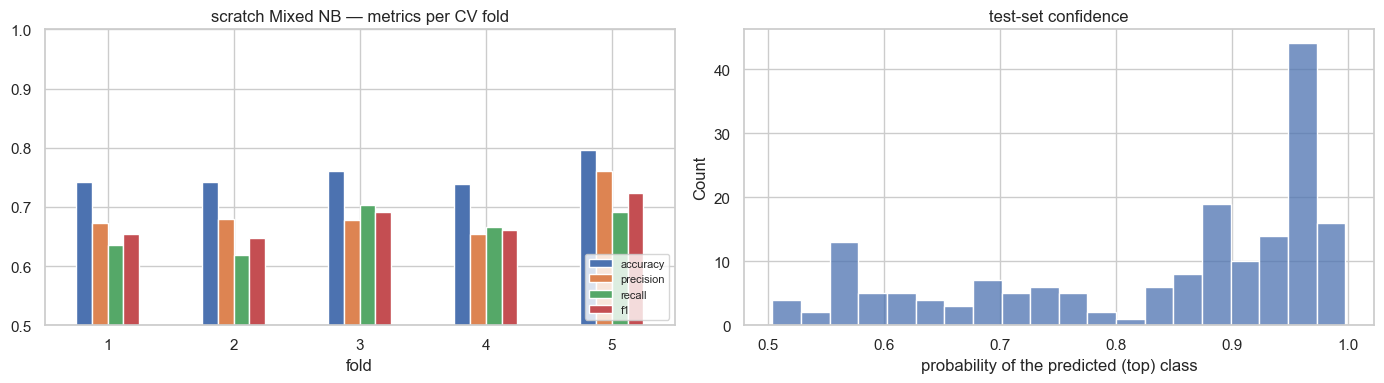

saved 179 rows to test_top_class_probabilities.csv; mean top-class probability = 0.834


,P(died),P(survived),top class,P(top class),true
784,0.967,0.033,0,0.967,0
382,0.969,0.031,0,0.969,0
263,0.616,0.384,0,0.616,0
647,0.212,0.788,1,0.788,1
238,0.881,0.119,0,0.881,0
758,0.970,0.030,0,0.970,0
29,0.968,0.032,0,0.968,0
46,0.936,0.064,0,0.936,0
715,0.846,0.154,0,0.846,0
885,0.432,0.568,1,0.568,0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cv_nb.plot.bar(ax=ax[0], rot=0); ax[0].set_ylim(0.5, 1); ax[0].set_title('scratch Mixed NB — metrics per CV fold'); ax[0].legend(loc='lower right', fontsize=8)
proba = nb.predict_proba(X_te)
top = proba.max(1)
sns.histplot(top, bins=20, ax=ax[1]); ax[1].set_xlabel('probability of the predicted (top) class'); ax[1].set_title('test-set confidence')
plt.tight_layout(); savefig('q1_cv_nb'); plt.show()

top_df = pd.DataFrame({'P(died)': proba[:, 0], 'P(survived)': proba[:, 1], 'top class': nb.predict(X_te),
                       'P(top class)': top, 'true': y_te}, index=X_te.index).round(3)
top_df.to_csv('test_top_class_probabilities.csv')
results['q1_top_prob'] = {'mean': float(top.mean()), 'acc_when_conf_gt_0.9': float(np.mean(top_df.loc[top > 0.9, 'top class'] == top_df.loc[top > 0.9, 'true'])),
                          'n_conf_gt_0.9': int((top > 0.9).sum()), 'n_test': len(top)}
print(f'saved {len(top_df)} rows to test_top_class_probabilities.csv; mean top-class probability = {top.mean():.3f}')
top_df.head(10)

### 6. Scratch vs. scikit-learn
sklearn has no single mixed NB, but the same model can be assembled from `CategoricalNB` (categorical features, α = 1) and `GaussianNB` (continuous features). Each one includes the class prior, so the prior is subtracted once when their log-probabilities are added. If my implementation is correct, the predictions should match exactly.

In [8]:
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.preprocessing import OrdinalEncoder

class SklearnMixedNB:
    def fit(self, X, y):
        self.enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(X[CAT])
        self.cnb = CategoricalNB(alpha=1.0).fit(self.enc.transform(X[CAT]), y)
        self.gnb = GaussianNB().fit(X[CONT], y)
        return self
    def predict_proba(self, X):
        jll = (self.cnb.predict_joint_log_proba(self.enc.transform(X[CAT])) + self.gnb.predict_joint_log_proba(X[CONT])
               - self.cnb.class_log_prior_)
        jll -= jll.max(1, keepdims=True)
        p = np.exp(jll); return p / p.sum(1, keepdims=True)
    def predict(self, X):
        return self.predict_proba(X).argmax(1)

sk_mixed = SklearnMixedNB().fit(X_tr, y_tr)
X_tr_num = X_tr.assign(Sex=(X_tr['Sex'] == 'male').astype(int), Embarked=X_tr['Embarked'].map({'S': 0, 'C': 1, 'Q': 2}))
X_te_num = X_te.assign(Sex=(X_te['Sex'] == 'male').astype(int), Embarked=X_te['Embarked'].map({'S': 0, 'C': 1, 'Q': 2}))
gnb_all = GaussianNB().fit(X_tr_num, y_tr)

agree = np.mean(sk_mixed.predict(X_te) == nb.predict(X_te))
max_diff = np.abs(sk_mixed.predict_proba(X_te) - nb.predict_proba(X_te)).max()
cmp = pd.DataFrame({
    'scratch Mixed NB': cross_validate(lambda: MixedNaiveBayes(CAT, CONT), X_tr, y_tr).mean(),
    'sklearn CategoricalNB+GaussianNB': cross_validate(SklearnMixedNB, X_tr, y_tr).mean(),
    'sklearn GaussianNB (all features)': cross_validate(GaussianNB, X_tr_num, y_tr).mean(),
}).T
cmp['test accuracy'] = [nb_test_acc, np.mean(sk_mixed.predict(X_te) == y_te), np.mean(gnb_all.predict(X_te_num) == y_te)]
results['q1_compare'] = cmp.round(4).to_dict('index')
results['q1_agreement'] = {'prediction_agreement': float(agree), 'max_prob_diff': float(max_diff)}
print(f'prediction agreement scratch vs sklearn: {agree:.2%} | max probability difference: {max_diff:.2e}')
cmp.round(4)

prediction agreement scratch vs sklearn: 100.00% | max probability difference: 1.02e-10


,accuracy,precision,recall,f1,test accuracy
scratch Mixed NB,0.7557,0.6892,0.6632,0.6754,0.7877
sklearn CategoricalNB+GaussianNB,0.7557,0.6892,0.6632,0.6754,0.7877
sklearn GaussianNB (all features),0.7627,0.6609,0.7913,0.7192,0.7598


### 7. Another model — logistic regression and random forest, 5-fold CV

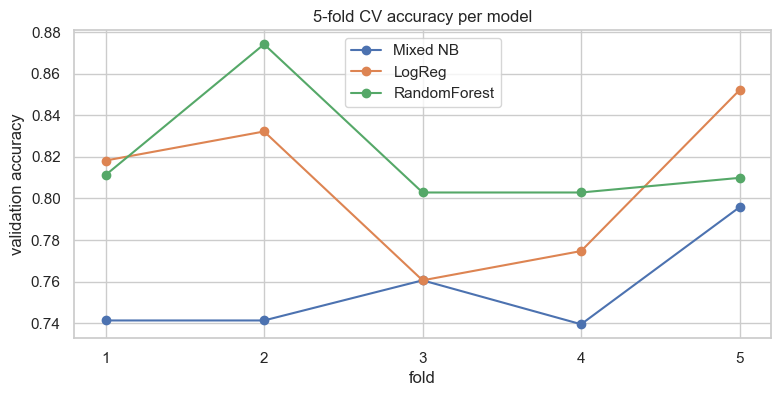

,accuracy,precision,recall,f1,test accuracy
Mixed NB (scratch),0.7557,0.6892,0.6632,0.6754,0.7877
Logistic regression,0.8075,0.7547,0.7358,0.7441,0.7486
Random forest,0.8202,0.8064,0.6995,0.7476,0.7709


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import make_column_transformer

def logreg():
    pre = make_column_transformer((OneHotEncoder(handle_unknown='ignore'), CAT), (StandardScaler(), CONT))
    return make_pipeline(pre, LogisticRegression(max_iter=1000))

def forest():
    pre = make_column_transformer((OneHotEncoder(handle_unknown='ignore'), CAT), ('passthrough', CONT))
    return make_pipeline(pre, RandomForestClassifier(n_estimators=300, max_depth=6, random_state=SEED))

cv_lr, cv_rf = cross_validate(logreg, X_tr, y_tr), cross_validate(forest, X_tr, y_tr)
summary = pd.DataFrame({'Mixed NB (scratch)': cv_nb.mean(), 'Logistic regression': cv_lr.mean(), 'Random forest': cv_rf.mean()}).T
summary['test accuracy'] = [nb_test_acc, np.mean(logreg().fit(X_tr, y_tr).predict(X_te) == y_te),
                            np.mean(forest().fit(X_tr, y_tr).predict(X_te) == y_te)]
results['q1_models'] = summary.round(4).to_dict('index')

fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({'Mixed NB': cv_nb['accuracy'], 'LogReg': cv_lr['accuracy'], 'RandomForest': cv_rf['accuracy']}).plot(marker='o', ax=ax)
ax.set_xlabel('fold'); ax.set_ylabel('validation accuracy'); ax.set_title('5-fold CV accuracy per model'); ax.set_xticks(range(1, 6))
savefig('q1_models'); plt.show()
summary.round(4)

# Question 2 — Seeds dataset (only NumPy / pandas / Matplotlib / Seaborn)

In [10]:
seeds = pd.read_csv('data/seeds.csv')
NAMES = ['Area', 'Perimeter', 'Compactness', 'Kernel length', 'Kernel width', 'Asymmetry coeff.', 'Groove length']
seeds.columns = NAMES + ['Class']
Xs, ys = seeds[NAMES].values, seeds['Class'].values
CLASSES = np.array([1, 2, 3])
print(seeds.shape, '| class counts:', dict(zip(*np.unique(ys, return_counts=True))))

(210, 8) | class counts: {np.int64(1): np.int64(70), np.int64(2): np.int64(70), np.int64(3): np.int64(70)}


### a. Distribution of samples

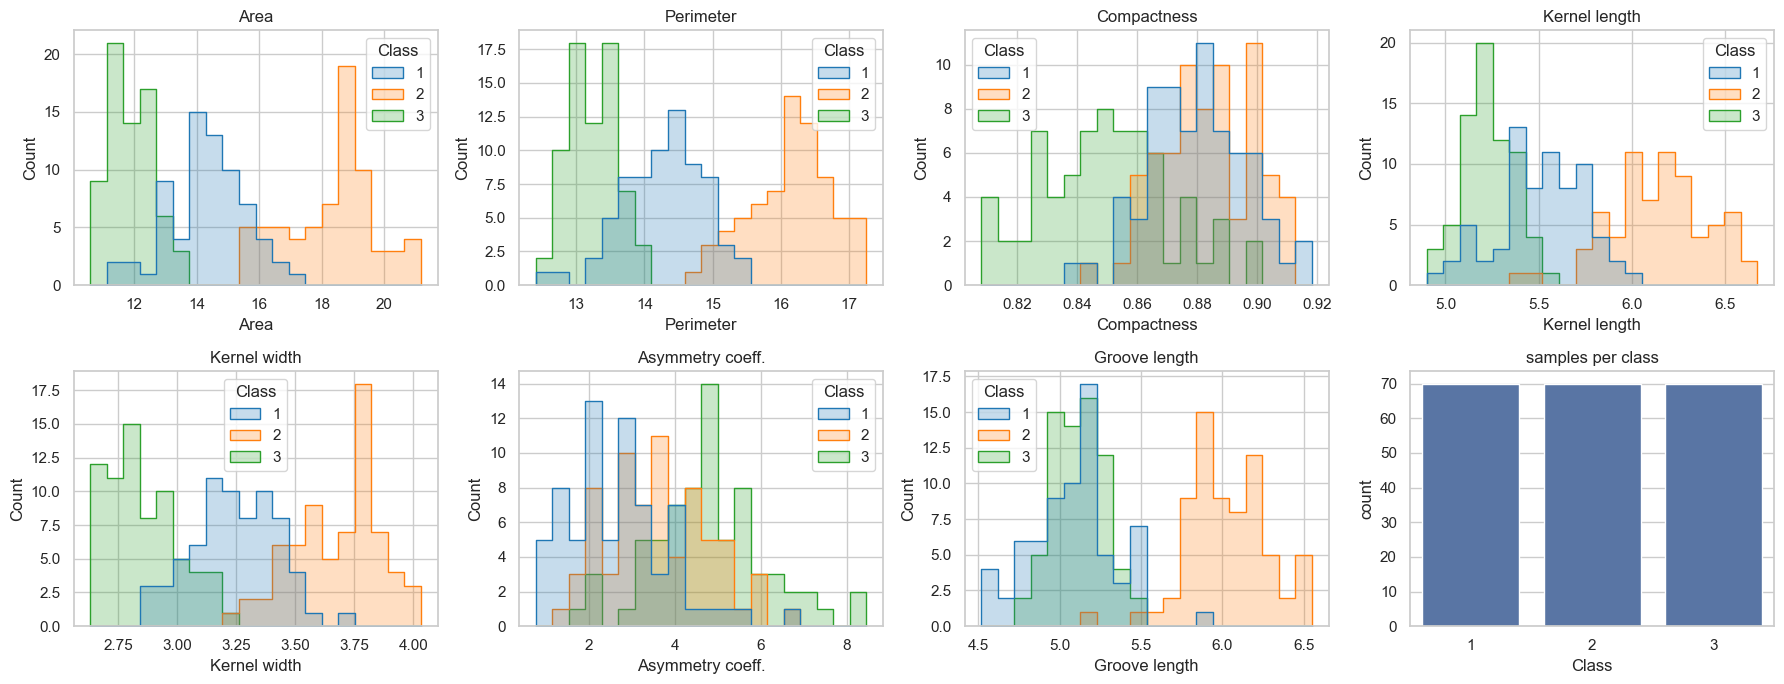

In [11]:
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for a, col in zip(ax.flat, NAMES):
    sns.histplot(data=seeds, x=col, hue='Class', bins=20, element='step', palette='tab10', ax=a)
    a.set_title(col)
sns.countplot(data=seeds, x='Class', ax=ax.flat[-1]); ax.flat[-1].set_title('samples per class')
plt.tight_layout(); savefig('q2a_distribution'); plt.show()

### b. Prior probabilities

In [12]:
priors = {int(c): float(np.mean(ys == c)) for c in CLASSES}
results['q2_priors'] = priors
priors

{1: 0.3333333333333333, 2: 0.3333333333333333, 3: 0.3333333333333333}

### c. Discretisation from scratch (no pandas / sklearn / scipy)
Each feature is cut into equal-width bins between its minimum and maximum. The number of bins comes from **Sturges' rule**, k = ⌈log₂ n⌉ + 1 = 9 for n = 210. That gives enough resolution to show each class's shape while keeping ≈ 23 samples per bin on average, which matters because each bin's probability is estimated per class. Only plain Python and NumPy arithmetic are used. A value equal to the maximum goes into the last bin.

In [13]:
def sturges_bins(n):
    k, power = 0, 1
    while power < n:            # ceil(log2 n) without a library call
        power *= 2; k += 1
    return k + 1

def fit_bins(column, n_bins):
    lo, hi = column.min(), column.max()
    width = (hi - lo) / n_bins
    return [lo + i * width for i in range(n_bins + 1)]

def discretize(column, edges):
    n_bins = len(edges) - 1
    out = np.empty(len(column), dtype=int)
    for i, v in enumerate(column):
        b = 0
        while b < n_bins - 1 and v >= edges[b + 1]:
            b += 1
        out[i] = b
    return out

N_BINS = sturges_bins(len(Xs))
edges = [fit_bins(Xs[:, j], N_BINS) for j in range(Xs.shape[1])]
Xd = np.column_stack([discretize(Xs[:, j], edges[j]) for j in range(Xs.shape[1])])
print('bins per feature:', N_BINS)
print('bin occupancy for Area:', np.bincount(Xd[:, 0], minlength=N_BINS))

bins per feature: 9
bin occupancy for Area: [34 41 25 26 22 14 17 22  9]


### d. Likelihoods (class-conditional probabilities)
P(bin = b | class = c) for every feature, bin and class, with Laplace smoothing (+1). Without smoothing, an empty bin would get probability 0 and wipe out the whole Naive Bayes product.

In [14]:
def likelihoods(Xd, y, n_bins, alpha=1):
    L = np.zeros((Xd.shape[1], len(CLASSES), n_bins))
    for j in range(Xd.shape[1]):
        for k, c in enumerate(CLASSES):
            counts = np.bincount(Xd[y == c, j], minlength=n_bins)
            L[j, k] = (counts + alpha) / (counts.sum() + alpha * n_bins)
    return L

L = likelihoods(Xd, ys, N_BINS)
results['q2_likelihood_area'] = {f'class {c}': L[0, k].round(3).tolist() for k, c in enumerate(CLASSES)}
pd.DataFrame(L[0], index=[f'class {c}' for c in CLASSES], columns=[f'bin {b}' for b in range(N_BINS)]).round(3)

,bin 0,bin 1,bin 2,bin 3,bin 4,bin 5,bin 6,bin 7,bin 8
class 1,0.038,0.114,0.266,0.342,0.165,0.038,0.013,0.013,0.013
class 2,0.013,0.013,0.013,0.013,0.139,0.165,0.228,0.291,0.127
class 3,0.418,0.430,0.076,0.013,0.013,0.013,0.013,0.013,0.013


### e. Count of each unique (binned) value per class, compared with the distribution

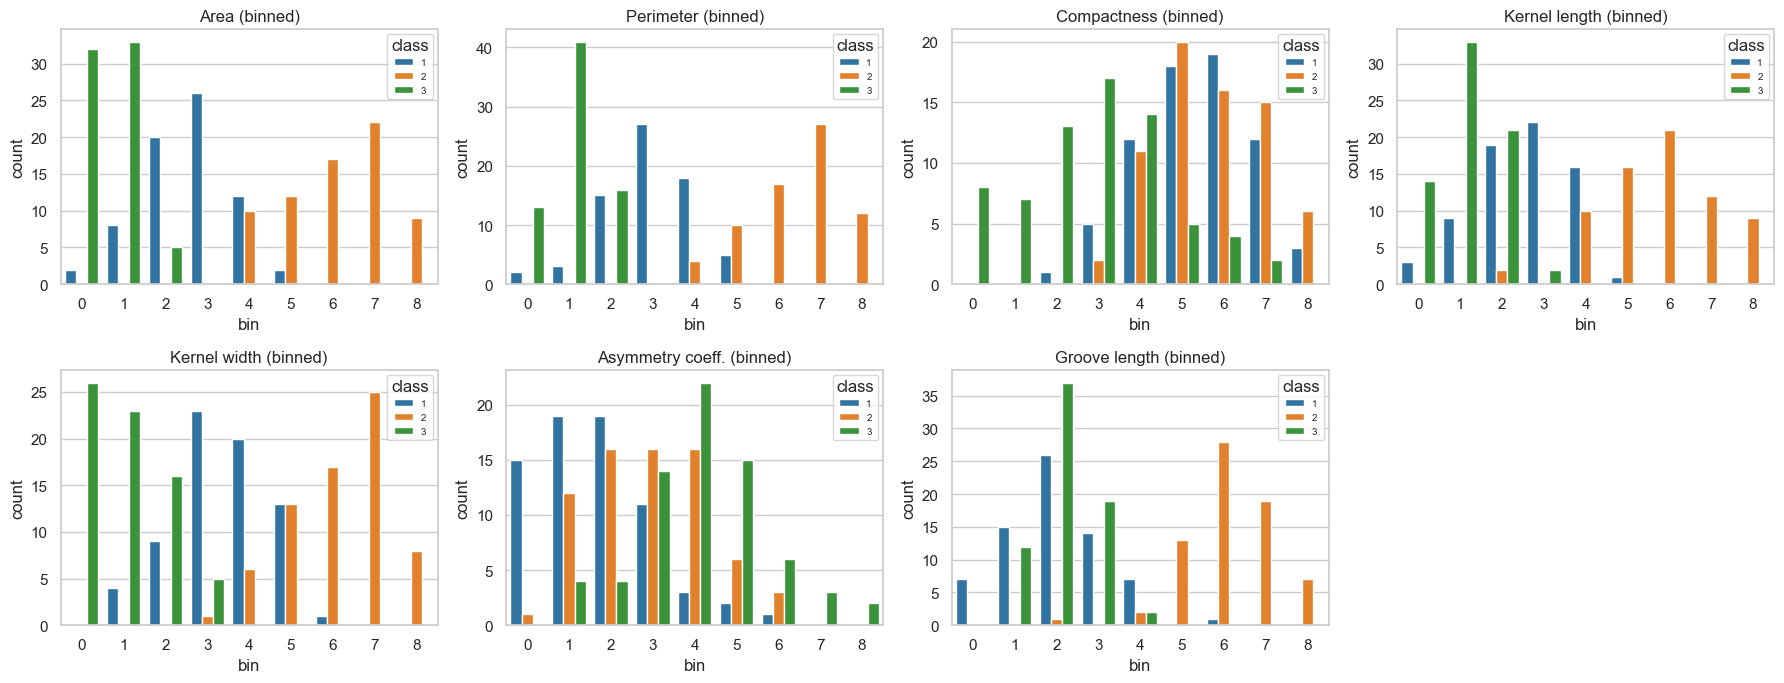

In [15]:
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
long = pd.DataFrame(Xd, columns=NAMES).assign(Class=ys).melt(id_vars='Class', var_name='feature', value_name='bin')
for a, col in zip(ax.flat, NAMES):
    sns.countplot(data=long[long['feature'] == col], x='bin', hue='Class', palette='tab10', ax=a, order=range(N_BINS))
    a.set_title(f'{col} (binned)'); a.legend(fontsize=7, title='class')
ax.flat[-1].axis('off')
plt.tight_layout(); savefig('q2e_counts'); plt.show()

The binned counts have the same shape as the histograms in (a): the class-3 peak in the lowest Area/Perimeter bins, class 2 in the highest, and class 1 in the middle all carry over. Binning keeps the information about which class sits where while coarsening the detail. Compactness and Asymmetry overlap the most across classes in both plots, so they will contribute the least evidence.

### f. Posterior probabilities
$P(c \mid x) \propto P(c)\prod_j P(x_j \mid c)$, computed in log space and normalised. The parameters are estimated on a 70% split and the posteriors are evaluated on the held-out 30%, so the plot shows genuine generalisation.

In [16]:
rng = np.random.default_rng(SEED)
idx = rng.permutation(len(ys))
tr_idx, te_idx = idx[:int(0.7 * len(ys))], idx[int(0.7 * len(ys)):]
edges_tr = [fit_bins(Xs[tr_idx, j], N_BINS) for j in range(Xs.shape[1])]
Xd_tr = np.column_stack([discretize(Xs[tr_idx, j], edges_tr[j]) for j in range(Xs.shape[1])])
Xd_te = np.column_stack([discretize(Xs[te_idx, j], edges_tr[j]) for j in range(Xs.shape[1])])
Xd_te = np.clip(Xd_te, 0, N_BINS - 1)       # test values below the train minimum fall into bin 0
L_tr = likelihoods(Xd_tr, ys[tr_idx], N_BINS)
prior_tr = np.array([np.mean(ys[tr_idx] == c) for c in CLASSES])

def posterior(Xd, L, prior):
    logp = np.tile(np.log(prior), (len(Xd), 1))
    for j in range(Xd.shape[1]):
        logp += np.log(L[j][:, Xd[:, j]]).T
    logp -= logp.max(1, keepdims=True)
    p = np.exp(logp)
    return p / p.sum(1, keepdims=True)

post = posterior(Xd_te, L_tr, prior_tr)
pred = CLASSES[post.argmax(1)]
y_hold = ys[te_idx]
acc = np.mean(pred == y_hold)
results['q2_posterior'] = {'test_acc': float(acc), 'n_test': int(len(te_idx)),
                           'train_acc': float(np.mean(CLASSES[posterior(Xd_tr, L_tr, prior_tr).argmax(1)] == ys[tr_idx])),
                           'confusion': pd.crosstab(y_hold, pred).to_dict()}
print(f'held-out accuracy = {acc:.4f} on {len(te_idx)} samples')
print(pd.crosstab(pd.Series(y_hold, name='true'), pd.Series(pred, name='predicted')))

held-out accuracy = 0.9524 on 63 samples
predicted   1   2   3
true                 
1          15   0   2
2           0  20   0
3           1   0  25


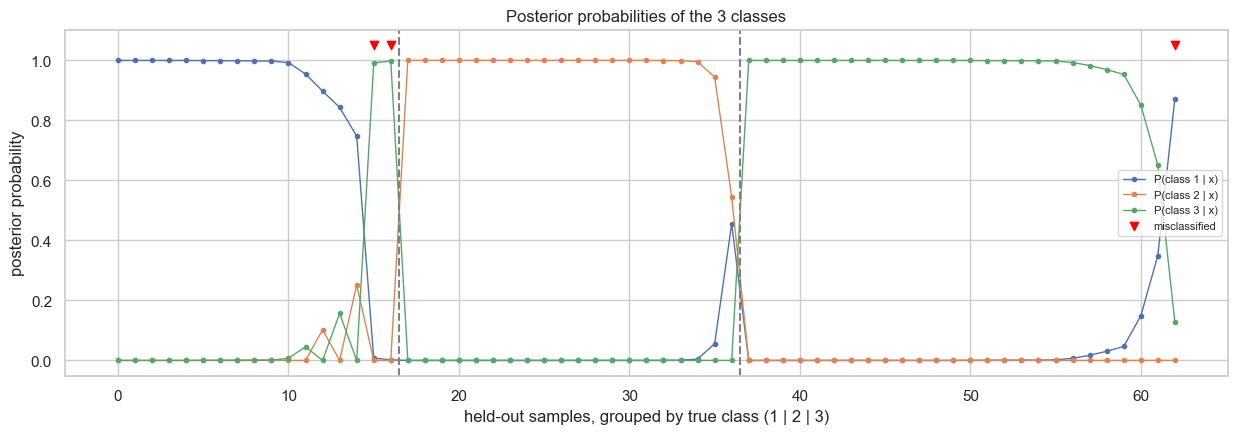

In [17]:
true_post = post[np.arange(len(y_hold)), y_hold - 1]
order = np.lexsort((-true_post, y_hold))      # within each class: most confident in the true class first
fig, ax = plt.subplots(figsize=(15, 4.5))
for k, c in enumerate(CLASSES):
    ax.plot(post[order, k], 'o-', ms=3, lw=1, label=f'P(class {c} | x)')
bounds = np.cumsum([np.sum(y_hold == c) for c in CLASSES])[:-1]
for b in bounds:
    ax.axvline(b - 0.5, c='grey', ls='--')
wrong = np.nonzero(pred[order] != y_hold[order])[0]
ax.scatter(wrong, np.full(len(wrong), 1.05), marker='v', c='red', label='misclassified', zorder=5)
ax.set_xlabel('held-out samples, grouped by true class (1 | 2 | 3)'); ax.set_ylabel('posterior probability')
ax.set_title('Posterior probabilities of the 3 classes'); ax.legend(loc='center right', fontsize=8)
savefig('q2f_posteriors'); plt.show()

with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=str)